In [14]:
# Load Dataset

df = pd.read_csv("house_price_dataset_sample.csv")   

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows")
print(df.head())

print("\nLast 5 Rows")
print(df.tail())

print("\nDataset Information")
print(df.info())

print("\nMissing Values")
print(df.isnull().sum())

Dataset Shape: (200, 15)

First 5 Rows
   bedrooms  bathrooms  living_area  lot_area  floors  waterfront  views  \
0         1          2         3993      5237       1           1      4   
1         4          4         3220      6408       1           1      2   
2         4          2         1621      6121       2           1      4   
3         3          3         3901      1768       3           1      3   
4         3          2         2247      6747       3           0      3   

   grade  basement_area  built_year   latitude  longitude  schools_nearby  \
0      9            361        1982  19.062063  72.566421               8   
1      3            886        2001  19.458262  72.550909               5   
2      3            991        2000  19.129030  72.828547               9   
3      4            380        1991  19.152327  72.710533               1   
4      2            149        1985  19.632283  72.026578               2   

   airport_distance_km       price  
0   

In [13]:
# Import Essential Libraries

import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Train-Test Split
from sklearn.model_selection import train_test_split

# Algorithms
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

# Evaluation Metrics
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Ignore Warnings
import warnings
warnings.filterwarnings('ignore')

In [15]:
# ==========================
# DATA PREPROCESSING
# ==========================

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Fill missing values

for col in df.columns:

    if df[col].dtype == 'object':
        df[col].fillna(df[col].mode()[0], inplace=True)

    else:
        df[col].fillna(df[col].median(), inplace=True)

# Remove duplicate records

print("\nDuplicate Rows:", df.duplicated().sum())

df.drop_duplicates(inplace=True)

# Handle categorical columns

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = le.fit_transform(df[col])

# Detect Outliers using IQR

numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[
        (df[col] >= lower) &
        (df[col] <= upper)
    ]

print("\nDataset Shape After Outlier Removal:", df.shape)

# Feature Scaling

from sklearn.preprocessing import StandardScaler

X = df.drop('price', axis=1)
y = df['price']

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

print("\nPreprocessing Completed Successfully")
print(X.head())

Missing Values:
bedrooms               0
bathrooms              0
living_area            0
lot_area               0
floors                 0
waterfront             0
views                  0
grade                  0
basement_area          0
built_year             0
latitude               0
longitude              0
schools_nearby         0
airport_distance_km    0
price                  0
dtype: int64

Duplicate Rows: 0

Dataset Shape After Outlier Removal: (200, 15)

Preprocessing Completed Successfully
   bedrooms  bathrooms  living_area  lot_area    floors  waterfront     views  \
0 -1.506377  -0.394514     1.612689  0.323277 -1.180603    0.960769  1.318209   
1  0.703467   1.419344     0.886005  0.907084 -1.180603    0.960769 -0.118531   
2  0.703467  -0.394514    -0.617188  0.763999  0.062137    0.960769  1.318209   
3 -0.033148   0.512415     1.526201 -1.406206  1.304877    0.960769  0.599839   
4 -0.033148  -0.394514    -0.028696  1.076093  1.304877   -1.040833  0.599839   

    

In [16]:
# Features and Target

X = df.drop("price", axis=1)
y = df["price"]

# Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Create Models

lr_model = LinearRegression()

dt_model = DecisionTreeRegressor(
    random_state=42
)

rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

gb_model = GradientBoostingRegressor(
    random_state=42
)

print("Models Created Successfully")

Models Created Successfully


In [17]:
# Train Models

lr_model.fit(X_train, y_train)

dt_model.fit(X_train, y_train)

rf_model.fit(X_train, y_train)

gb_model.fit(X_train, y_train)

print("All Models Trained Successfully")

All Models Trained Successfully


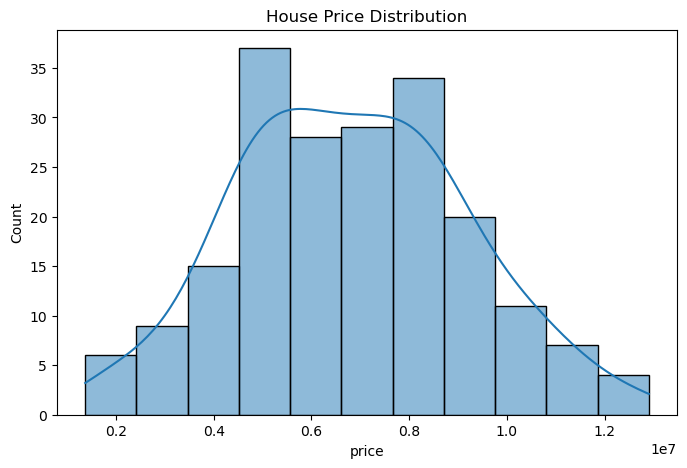

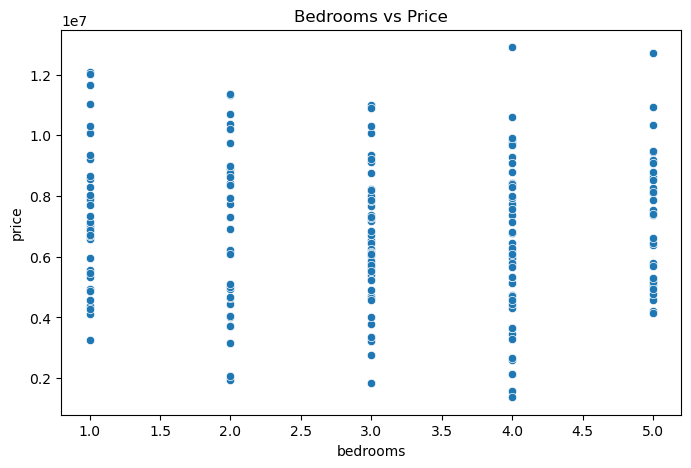

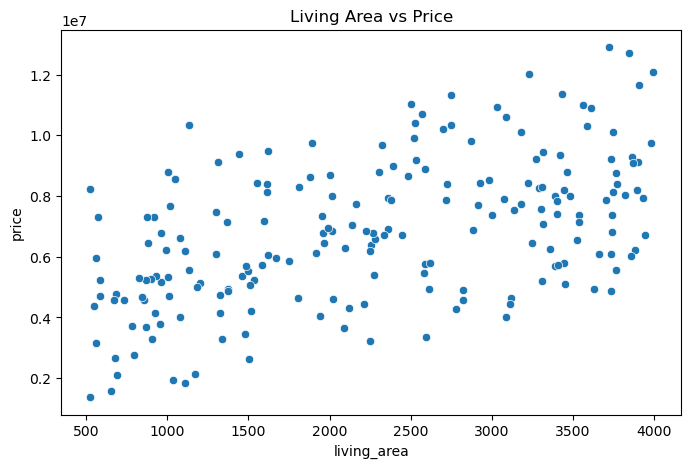

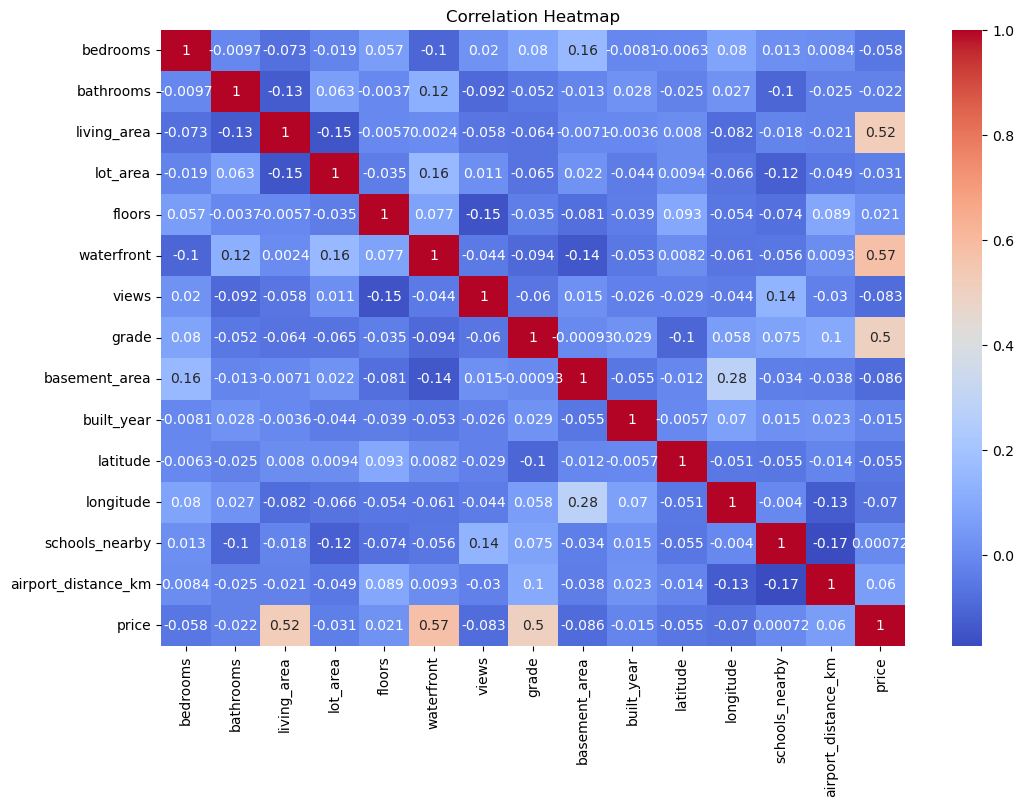

In [18]:
# Chart 1 - Price Distribution

plt.figure(figsize=(8,5))
sns.histplot(df["price"], kde=True)
plt.title("House Price Distribution")
plt.show()


# Chart 2 - Bedrooms vs Price

plt.figure(figsize=(8,5))
sns.scatterplot(x=df["bedrooms"], y=df["price"])
plt.title("Bedrooms vs Price")
plt.show()


# Chart 3 - Living Area vs Price

plt.figure(figsize=(8,5))
sns.scatterplot(x=df["living_area"], y=df["price"])
plt.title("Living Area vs Price")
plt.show()


# Chart 4 - Correlation Heatmap

plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [19]:
# Predictions

lr_pred = lr_model.predict(X_test)
dt_pred = dt_model.predict(X_test)
rf_pred = rf_model.predict(X_test)
gb_pred = gb_model.predict(X_test)

# R² Scores

lr_r2 = r2_score(y_test, lr_pred)
dt_r2 = r2_score(y_test, dt_pred)
rf_r2 = r2_score(y_test, rf_pred)
gb_r2 = r2_score(y_test, gb_pred)

print("Linear Regression R² :", round(lr_r2,4))
print("Decision Tree R²     :", round(dt_r2,4))
print("Random Forest R²     :", round(rf_r2,4))
print("Gradient Boosting R² :", round(gb_r2,4))

Linear Regression R² : 0.9081
Decision Tree R²     : 0.7004
Random Forest R²     : 0.897
Gradient Boosting R² : 0.9107


In [20]:
scores = {
    "Linear Regression": lr_r2,
    "Decision Tree": dt_r2,
    "Random Forest": rf_r2,
    "Gradient Boosting": gb_r2
}

best_model_name = max(scores, key=scores.get)

print("Best Model:", best_model_name)
print("Best Score:", scores[best_model_name])

Best Model: Gradient Boosting
Best Score: 0.9106998707689193


Confusion Matrix
[[20  0]
 [ 1 19]]


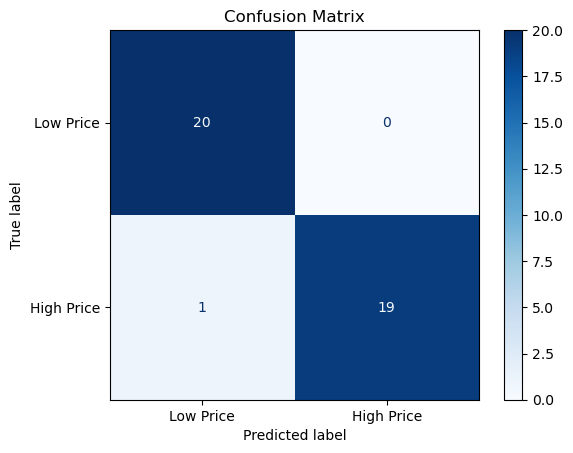

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Predict
y_pred = gb_model.predict(X_test)   # Replace 'model' with your trained model

# Threshold
threshold = np.median(y_test)

# Convert regression output into classes
y_test_class = np.where(y_test >= threshold, 1, 0)
y_pred_class = np.where(y_pred >= threshold, 1, 0)

# Confusion Matrix
cm = confusion_matrix(y_test_class, y_pred_class)

print("Confusion Matrix")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low Price", "High Price"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

Confusion Matrix
[[19  1]
 [ 3 17]]


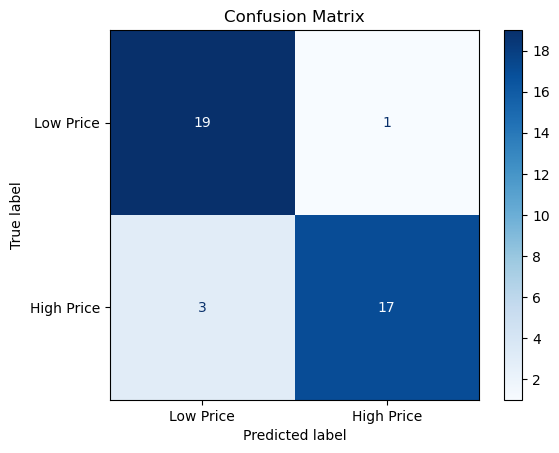

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Predict
y_pred = lr_model.predict(X_test)   # Replace 'model' with your trained model

# Threshold
threshold = np.median(y_test)

# Convert regression output into classes
y_test_class = np.where(y_test >= threshold, 1, 0)
y_pred_class = np.where(y_pred >= threshold, 1, 0)

# Confusion Matrix
cm = confusion_matrix(y_test_class, y_pred_class)

print("Confusion Matrix")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low Price", "High Price"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

                Feature  Importance
7                 grade    0.322881
5            waterfront    0.313223
2           living_area    0.302046
13  airport_distance_km    0.007266
11            longitude    0.007235
10             latitude    0.007231
3              lot_area    0.007087
6                 views    0.006066
8         basement_area    0.006024
9            built_year    0.005140
12       schools_nearby    0.004789
0              bedrooms    0.004055
1             bathrooms    0.003734
4                floors    0.003225


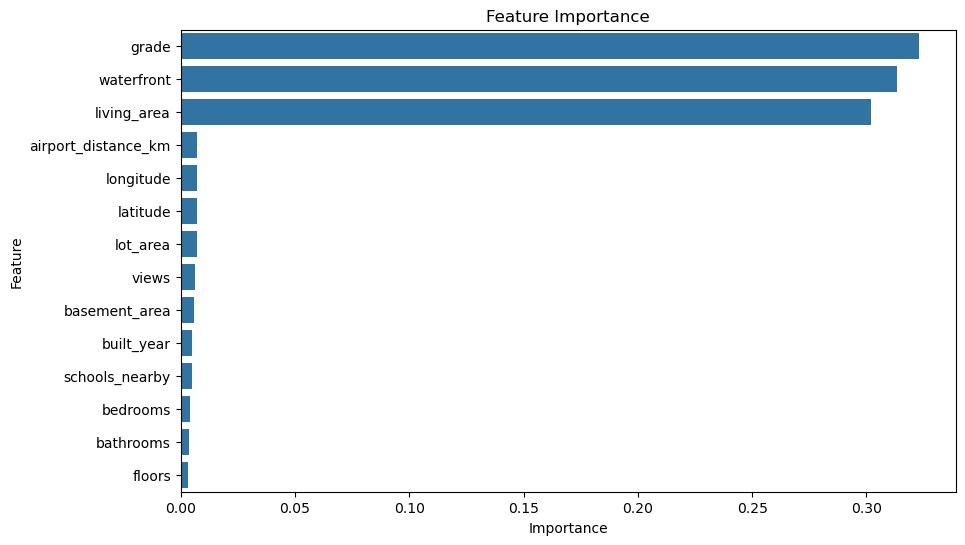

In [22]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

plt.figure(figsize=(10,6))
sns.barplot(
    x="Importance",
    y="Feature",
    data=feature_importance
)
plt.title("Feature Importance")
plt.show()

In [23]:
# Use first record as sample test data

sample_data = pd.DataFrame([{
    'bedrooms':4,
    'bathrooms':3,
    'living_area':2500,
    'lot_area':5000,
    'floors':2,
    'waterfront':0,
    'views':3,
    'grade':8,
    'basement_area':400,
    'built_year':2015,
    'latitude':47.5,
    'longitude':-122.2,
    'schools_nearby':4,
    'airport_distance_km':20
}])

sample_data

,bedrooms,bathrooms,living_area,lot_area,floors,waterfront,views,grade,basement_area,built_year,latitude,longitude,schools_nearby,airport_distance_km
0,4,3,2500,5000,2,0,3,8,400,2015,47.5,-122.2,4,20


In [24]:
# Using Best Model

best_model = gb_model

predicted_price = best_model.predict(sample_data)

print("Predicted House Price = ₹", round(predicted_price[0], 2))

Predicted House Price = ₹ 7218713.6


           Algorithm  R2 Score  Accuracy (%)
3  Gradient Boosting  0.910700     91.069987
0  Linear Regression  0.908058     90.805802
2      Random Forest  0.896965     89.696470
1      Decision Tree  0.700423     70.042308


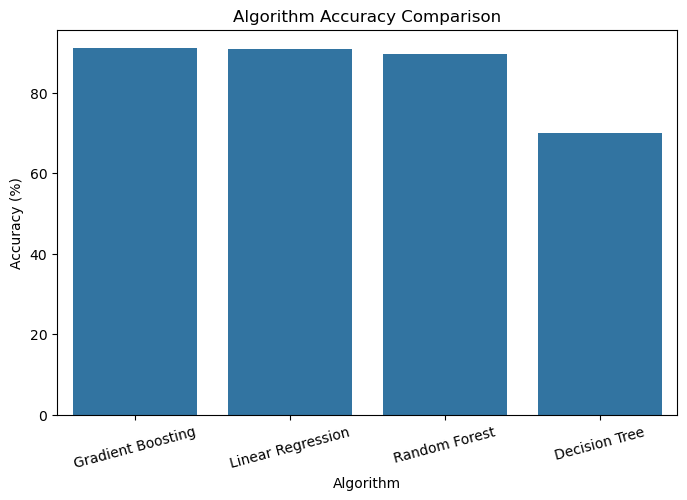

In [25]:
comparison = pd.DataFrame({
    "Algorithm": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "R2 Score": [
        lr_r2,
        dt_r2,
        rf_r2,
        gb_r2
    ]
})

comparison["Accuracy (%)"] = comparison["R2 Score"] * 100

comparison = comparison.sort_values(
    by="Accuracy (%)",
    ascending=False
)

print(comparison)

plt.figure(figsize=(8,5))
sns.barplot(
    x="Algorithm",
    y="Accuracy (%)",
    data=comparison
)
plt.title("Algorithm Accuracy Comparison")
plt.xticks(rotation=15)
plt.show()